# **# Methodology: Pothole Detection using RF-DETR**

## 1. Introduction to RF-DETR
**RF-DETR (Real-time Flexible Detection Transformer)** is a state-of-the-art object detection architecture developed by Roboflow. It represents a significant shift in computer vision by bringing the power of **Transformers** to real-time edge applications. While traditional models like YOLO rely on convolutional neural networks (CNNs), RF-DETR leverages self-attention mechanisms to understand global context, making it highly effective for identifying objects in complex environments like urban roads.

## 2. Technical Architecture & Core Components
The model architecture used in this project is built upon several key innovations:

* **Transformer Backbone:** Unlike CNNs that process images pixel-by-pixel in a local neighborhood, the Transformer architecture allows the model to relate every pixel to every other pixel simultaneously. This "Global Context" is crucial for pothole detection, as it helps the model distinguish between a shadow, a patch of water, and an actual structural road defect.
* **DINOv2 Integration:** This project utilizes the `dinov2_windowed_small` encoder. DINOv2 is a self-supervised vision transformer (ViT) that provides extremely rich feature representations, allowing the model to detect subtle textures and depth cues in the asphalt.
* **Real-Time Optimization:** Despite being transformer-based, RF-DETR is engineered for the "edge." It is designed to maintain high frame rates (FPS) on mobile or vehicle-mounted hardware without sacrificing the accuracy typically associated with much larger, slower models.

## 3. Benchmarks and SOTA Performance
RF-DETR is considered **State-of-the-Art (SOTA)** because it breaks several performance barriers:
* **Microsoft COCO Benchmark:** It is the first real-time model to exceed **60 AP (Average Precision)** on this industry-standard dataset.
* **RF100-VL Benchmark:** It achieves SOTA performance on the Roboflow 100-VL benchmark, which measures **Domain Adaptability**. This is particularly relevant for pothole detection, as the model must adapt to different road types, weather conditions, and lighting across various geographical regions.

## 4. Comparison: RF-DETR vs. Traditional Detectors
| Feature | Traditional Detectors (e.g., YOLOv5/v8) | RF-DETR |
| :--- | :--- | :--- |
| **Architecture** | Convolutional Neural Networks (CNN) | Vision Transformers (ViT) |
| **Spatial Awareness** | Local (limited by receptive field) | Global (Self-Attention mechanism) |
| **Accuracy** | High, but can struggle with complex scenes | SOTA (High precision even in varied domains) |
| **Deployment** | Excellent for Real-time | Real-time Performance + Transformer Accuracy |

## 5. Experimental Setup & Training Strategy
The implementation in this project followed a rigorous training pipeline to ensure the pothole detection model is both accurate and robust:

### A. Data Configuration
* **Source:** Custom Pothole Dataset via Roboflow.
* **Format:** COCO JSON format for standardized evaluation.
* **Image Scaling:** A square resize to **560px** was implemented, with multi-scale training reaching up to **840px** to ensure the model can detect both large craters and small emerging cracks.

### B. Hyperparameter Optimization
To achieve stable convergence on standard GPU hardware (like the NVIDIA T4), the following strategy was used:
* **Gradient Accumulation:** Used to simulate a larger "Global Batch Size" (set to 16). This ensures that the model learns from a diverse set of road images before updating its weights, leading to more stable training.
* **Reinitialization:** The detection head was specifically reinitialized to match the number of classes in the pothole dataset, ensuring the transformer queries are focused purely on road defects.

### C. Evaluation Metrics
The model is evaluated using:
* **mAP @ .5:.95:** The mean Average Precision across multiple Intersection over Union (IoU) thresholds.
* **AR @ 10:** Average Recall, measuring the model's ability to find all potholes in a given frame.

# How to Train RF-DETR Object Detection on a Custom Dataset


RF-DETR is a real-time, transformer-based object detection model architecture developed by Roboflow and released under the Apache 2.0 license.

![rf-detr-coco-rf100-vl-8](https://media.roboflow.com/rf-detr/charts.png)

RF-DETR is the first real-time model to exceed 60 AP on the [Microsoft COCO benchmark](https://cocodataset.org/#home) alongside competitive performance at base sizes. It also achieves state-of-the-art performance on [RF100-VL](https://github.com/roboflow/rf100-vl), an object detection benchmark that measures model domain adaptability to real world problems. RF-DETR is comparable speed to current real-time objection models.

![rf-detr-coco-results-2](https://media.roboflow.com/rf-detr/example_grid.png)

RF-DETR is small enough to run on the edge, making it an ideal model for deployments that need both strong accuracy and real-time performance.

## Environment setup

In [ ]:
# Mount drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

BASE_DIR = "/content/drive/MyDrive/PDP"
os.makedirs(BASE_DIR, exist_ok=True)

print("Working directory set to:", BASE_DIR)
print("Folder exists:", os.path.exists(BASE_DIR))

Working directory set to: /content/drive/MyDrive/PDP
Folder exists: True


In [ ]:
!ls /content/drive/MyDrive/PDP

dataset  pothole_detection_final.ipynb	test.txt


### Configure the API keys

To download model weights, we need to provide our HuggingFace Token. Follow these steps:

- Open your [`HuggingFace Settings`](https://huggingface.co/settings) page. Click `Access Tokens` then `New Token` to generate new token.
- In Colab, go to the left pane and click on `Secrets` (🔑). Store HuggingFace Access Token under the name `HF_TOKEN`.

### Check GPU availability

Let's make sure that we have access to GPU. We can use `nvidia-smi` command to do that. In case of any problems navigate to `Edit` -> `Notebook settings` -> `Hardware accelerator`, set it to `T4 GPU`, and then click `Save`.

In [ ]:
!nvidia-smi

Thu Apr  9 16:13:23 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   58C    P8             14W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
# confirm PyTorch actually sees the GPU.
import torch
print(torch.cuda.is_available())

True


### Install dependencies

Install the RF-DETR SDK

To get started, we need to install the RF-DETR SDK.



In [ ]:
!pip install -q rfdetr


## Download Dataset from Roboflow

I have used the following dataset from Roboflow. https://universe.roboflow.com/muhammadmoin-arxtl/potholes-detection-jbnou/dataset/1

In [ ]:
# Install Roboflow
!pip install roboflow

from roboflow import Roboflow
import os

rf = Roboflow(api_key="REDACTED_ROTATED_KEY")
project = rf.workspace("muhammadmoin-arxtl").project("potholes-detection-jbnou")
version = project.version(1)

# Set dataset path to Drive
dataset_path = os.path.join(BASE_DIR, "dataset")

dataset = version.download("coco", location=dataset_path)

print("Dataset downloaded to:", dataset_path)

  Using cached roboflow-1.3.1-py3-none-any.whl.metadata (10 kB)
  Using cached idna-3.7-py3-none-any.whl.metadata (9.9 kB)
Using cached roboflow-1.3.1-py3-none-any.whl (169 kB)
Using cached idna-3.7-py3-none-any.whl (66 kB)
  Attempting uninstall: idna
    Found existing installation: idna 3.11
    Uninstalling idna-3.11:
      Successfully uninstalled idna-3.11
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/drive/MyDrive/PDP/dataset in coco:: 100%|██████████| 673/673 [00:07<00:00, 95.76it/s]

Dataset downloaded to: /content/drive/MyDrive/PDP/dataset


In [ ]:
dataset_path = os.path.join(BASE_DIR, "dataset")

class DummyDataset:
    def __init__(self, location):
        self.location = location

dataset = DummyDataset(dataset_path)

print(dataset.location)

/content/drive/MyDrive/PDP/dataset


In [ ]:
dataset.location

'/content/drive/MyDrive/PDP/dataset'

## Train RF-DETR on custom dataset

### Choose the right `batch_size`

Different GPUs have different amounts of VRAM (video memory), which limits how much data they can handle at once during training. To make training work well on any machine, you can adjust two settings: `batch_size` and `grad_accum_steps`. These control how many samples are processed at a time. The key is to keep their product equal to 16 — that’s the recommended total batch size. For example, on powerful GPUs like the A100, set `batch_size=16` and `grad_accum_steps=1`. On smaller GPUs like the T4, use `batch_size=4` and `grad_accum_steps=4`. We use a method called gradient accumulation, which lets the model simulate training with a larger batch size by gradually collecting updates before adjusting the weights.

### Train with multiple GPUs

You can fine-tune RF-DETR on multiple GPUs using PyTorch’s Distributed Data Parallel (DDP). Create a `main.py` script that initializes your model and calls `.train()` as usual than run it in terminal.

```bash
python -m torch.distributed.launch \
    --nproc_per_node=8 \
    --use_env \
    main.py
```

Replace `8` in the `--nproc_per_node argument` with the number of GPUs you want to use. This approach creates one training process per GPU and splits the workload automatically. Note that your effective batch size is multiplied by the number of GPUs, so you may need to adjust your `batch_size` and `grad_accum_steps` to maintain the same overall batch size.

In [ ]:
!pip uninstall -y opencv-python-headless
!pip install opencv-python==4.8.0.76

Found existing installation: opencv-python-headless 4.10.0.84
Uninstalling opencv-python-headless-4.10.0.84:
  Successfully uninstalled opencv-python-headless-4.10.0.84
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.7/61.7 MB 13.9 MB/s eta 0:00:00
  Attempting uninstall: opencv-python
    Found existing installation: opencv-python 4.13.0.92
    Uninstalling opencv-python-4.13.0.92:
      Successfully uninstalled opencv-python-4.13.0.92


Resolved compatibility issue between Albumentations and OpenCV (headless vs full build)

In [ ]:
!pip install numpy==1.26.4

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 6.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.0/18.0 MB 108.4 MB/s eta 0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 2.0.2
    Uninstalling numpy-2.0.2:
      Successfully uninstalled numpy-2.0.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
roboflow 1.3.1 requires opencv-python-headless==4.10.0.84, which is not installed.
albumentations 2.0.8 requires opencv-python-headless>=4.9.0.80, which is not installed.
albucore 0.0.24 requires opencv-python-headless>=4.9.0.80, which is not installed.
shap 0.51.0 requires numpy>=2, but you have numpy 1.26.4 which is incompatible.
xarray-einstats 0.10.0 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
tobler 0.13.0 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
jaxlib

In [ ]:
!pip install "rfdetr[train,loggers]"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.2/49.2 kB 6.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.0/50.0 kB 6.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.6/40.6 kB 4.9 MB/s eta 0:00:00
  Using cached opencv_python_headless-4.10.0.84-cp37-abi3-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (20 kB)
INFO: pip is looking at multiple versions of wandb to determine which version is compatible with other requirements. This could take a while.
INFO: pip is looking at multiple versions of databricks-sdk to determine which version is compatible with other requirements. This could take a while.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.6/40.6 kB 4.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.6/40.6 kB 4.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.6/40.6 kB 3.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.6/40.6 kB 5.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━

In [ ]:
from rfdetr import RFDETRBase

model = RFDETRBase()
history = []

def callback2(data):
    history.append(data)

model.callbacks["on_fit_epoch_end"].append(callback2)

model.train(dataset_dir=dataset.location, epochs=30, batch_size=4, grad_accum_steps=4, lr=1e-4)

Val — Overall Metrics                      
┏━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃           mAP            ┃  mAR   ┃         F1 sweep         ┃
┡━━━━━━━━┯━━━━━━━━┯━━━━━━━━╇━━━━━━━━╇━━━━━━━━┯━━━━━━━━┯━━━━━━━━┩
│ 50:95  │   50   │   75   │  @500  │   F1   │  Prec  │ Recall │
├────────┼────────┼────────┼────────┼────────┼────────┼────────┤
│ 0.6116 │ 0.8737 │ 0.7034 │ 0.7441 │ 0.8432 │ 0.9141 │ 0.7826 │
└────────┴────────┴────────┴────────┴────────┴────────┴────────┘

                  Val — Per-class Metrics                  
┏━━━━━━━┳━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━┓
┃ Class ┃ AP 50:95 ┃     AR ┃     F1 ┃ Precision ┃ Recall ┃
┡━━━━━━━╇━━━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━┩
│ 0     │   0.6116 │ 0.7441 │ 0.8432 │    0.9141 │ 0.7826 │
└───────┴──────────┴────────┴────────┴───────────┴────────┘

[2026-04-09 17:45:50] [INFO] rf-detr - Best EMA mAP improved to 0.6255 (epoch 29)


INFO:pytorch_lightning.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=30` reached.


[2026-04-09 17:46:40] [INFO] rf-detr - Best total checkpoint saved from EMA (regular=0.6246, ema=0.6255)


The model shows high precision but relatively lower recall, indicating that while detections are accurate, some potholes are missed. Future improvements would focus on increasing recall through data augmentation, longer training, and tuning detection thresholds.

**Save model weights to MyDrive**

In [ ]:
import shutil
import os

DEST_PATH = os.path.join(BASE_DIR, "model_outputs")

# Create folder in Drive
os.makedirs(DEST_PATH, exist_ok=True)

# Copy entire output folder
shutil.copytree("/content/output", DEST_PATH, dirs_exist_ok=True)

print("Model outputs copied to:", DEST_PATH)

Model outputs copied to: /content/drive/MyDrive/PDP/model_outputs


In [ ]:
!ls /content/drive/MyDrive/PDP/model_outputs

checkpoint_19.ckpt
checkpoint_29.ckpt
checkpoint_9.ckpt
checkpoint_best_ema.pth
checkpoint_best_regular.pth
checkpoint_best_total.pth
events.out.tfevents.1775751452.616fc365905e.19703.0
hparams.yaml
last.ckpt
metrics.csv


In [ ]:
model

# Sanity Check
Check if we can load the trained model without errors, missing weights or compatibility issues.

RF-DETR is designed so you don’t manually load weights like typical PyTorch

In [ ]:
from rfdetr import RFDETRBase
import os

model_path = os.path.join(BASE_DIR, "model_outputs", "checkpoint_best_total.pth")

model = RFDETRBase(pretrain_weights=model_path)

print("Model loaded successfully")

[2026-04-09 18:07:06] [WARNING] rf-detr - Checkpoint has 2 classes but model is configured for 90. Using checkpoint class count (2). Pass num_classes=2 to suppress this warning.


Model loaded successfully


# **MODEL EVALUATION**

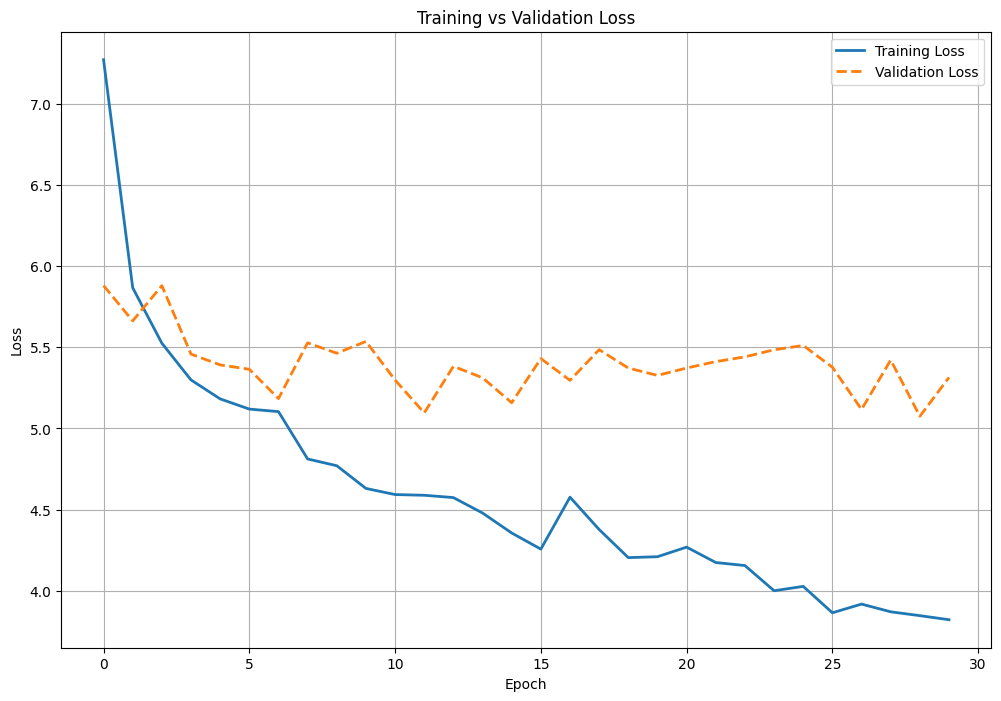

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os

metrics_path = os.path.join(BASE_DIR, "model_outputs", "metrics.csv")
df = pd.read_csv(metrics_path)

# Group by epoch and average values
df_epoch = df.groupby('epoch').mean(numeric_only=True).reset_index()

plt.figure(figsize=(12, 8))

plt.plot(df_epoch['epoch'], df_epoch['train/loss'], label='Training Loss', linewidth=2)
plt.plot(df_epoch['epoch'], df_epoch['val/loss'], label='Validation Loss', linewidth=2, linestyle='--')

plt.title('Training vs Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.show()

### 📊 Training vs Validation Loss Interpretation

The training and validation loss curves provide key insights into the model's learning behavior and generalization performance.

- **Consistent Training Convergence:**  
  The training loss shows a steady decline from approximately 7.3 to 3.8 across epochs, indicating that the model is effectively learning and optimizing its parameters.

- **Stable Validation Loss:**  
  The validation loss remains relatively stable (around 5.1–5.5) with minor fluctuations, suggesting that the model maintains consistent performance on unseen data.

- **Generalization Gap:**  
  A noticeable gap exists between training and validation loss, with training loss being significantly lower. This indicates mild overfitting, where the model fits the training data better than the validation data.

- **No Severe Overfitting:**  
  Despite the gap, the validation loss does not increase over time, which implies that overfitting is controlled and not degrading performance.

- **Learning Plateau:**  
  Validation loss stabilizes after early epochs, suggesting that the model reaches a performance plateau and further training may yield diminishing returns without additional tuning.

---

### ✅ Key Insight

The model demonstrates **strong learning capability with controlled overfitting**, achieving a good balance between fitting the training data and generalizing to unseen data.

### Average Precision

The graph below represents the Average Precision (AP) over training epochs across different Intersection Over Union (IOU) thresholds  (0.50 to 0.95, in steps of 0.05).



**Average Precision (AP)**

Average Precision (AP) is a key metric used to evaluate object detection models. It measures how well a model detects objects across different confidence thresholds by considering both precision and recall.

**Understanding Precision & Recall**

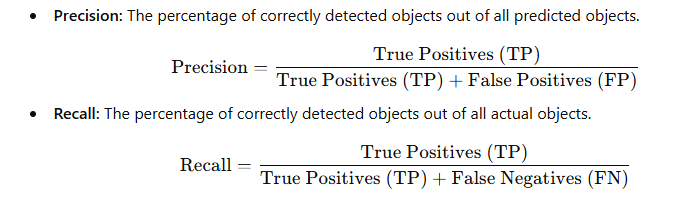

**How AP is Calculated**

**Precision-Recall (PR) Curve:**

The model predicts objects at different confidence scores (thresholds).

A Precision-Recall Curve is plotted by varying the threshold and computing precision vs. recall.

**Compute AP:**

The AP is the area under the Precision-Recall (PR) curve.

Higher AP means better object detection performance.

**AP (IoU=0.50:0.95) Meaning**

IoU (Intersection over Union) measures how much the predicted bounding box overlaps with the ground truth.

AP at IoU 0.50:0.95 is the mean AP calculated at multiple IoU thresholds (0.50 to 0.95, in steps of 0.05).



**Key Takeaways**

Good Model Performance: The AP value around 0.60 is relatively high, indicating decent object detection capability.

Training Convergence: The model stops improving significantly after ~10 epochs, meaning further training may not bring substantial gains.

### Average Recall

The graph below represents the Average Recall (AR) over training epochs across different Intersection Over Union (IOU) thresholds.



The AR starts at a lower value and increases rapidly in the first few epochs.

It then stabilizes around 0.32 - 0.34, with minor fluctuations.

The trend suggests the model is learning effectively but may still be improving gradually

**Average Recall (AR)** is a metric used in object detection to evaluate the model's ability to detect objects across different Intersection Over Union (IOU) thresholds. It is a mean recall over a range of IOU values, typically from 0.50 to 0.95 with steps of 0.05

**How AR is Calculated**

The recall is measured at multiple IoU thresholds (e.g., 0.50, 0.55, 0.60, ..., 0.95).

The average of these recall values gives the Average Recall (AR).



**Key Concepts**

Recall measures how many true positives the model correctly detects out of the total available ground-truth objects.

IoU (Intersection over Union) is the ratio of the overlapping area between the predicted bounding box and the ground truth box to the union of both areas.

Higher AR indicates that the model detects more objects correctly across various IoU thresholds.

### Results

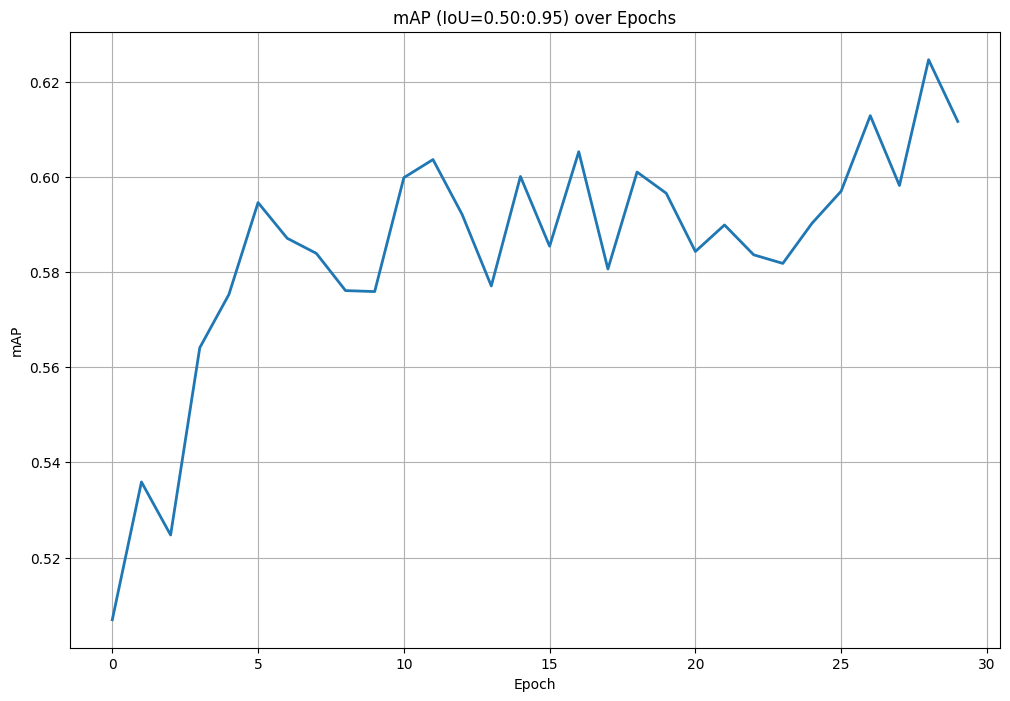

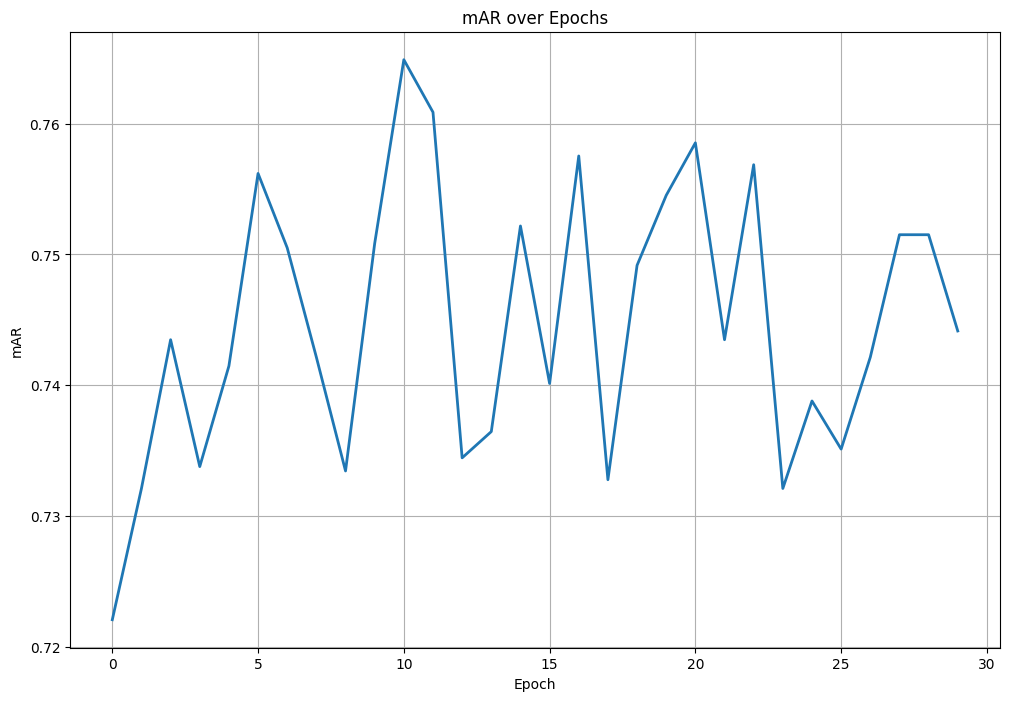

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os

metrics_path = os.path.join(BASE_DIR, "model_outputs", "metrics.csv")
df = pd.read_csv(metrics_path)

# Aggregate per epoch
df_epoch = df.groupby('epoch').mean(numeric_only=True).reset_index()

# ---- AP Plot ----
plt.figure(figsize=(12, 8))
plt.plot(df_epoch['epoch'], df_epoch['val/mAP_50_95'], linewidth=2)

plt.title('mAP (IoU=0.50:0.95) over Epochs')
plt.xlabel('Epoch')
plt.ylabel('mAP')
plt.grid(True)
plt.show()

# ---- AR Plot ----
plt.figure(figsize=(12, 8))
plt.plot(df_epoch['epoch'], df_epoch['val/mAR'], linewidth=2)

plt.title('mAR over Epochs')
plt.xlabel('Epoch')
plt.ylabel('mAR')
plt.grid(True)
plt.show()

### 📈 mAP and mAR Trends Interpretation

The mAP and mAR curves provide insight into the model’s detection accuracy and coverage across training epochs.

---

### 🔹 mAP (IoU=0.50:0.95)

- **Steady Performance Improvement:**  
  The mAP increases from approximately 0.51 to around 0.62, indicating that the model progressively improves its ability to localize and classify potholes accurately.

- **Early Rapid Learning:**  
  Significant gains are observed in the first few epochs, showing that the model quickly learns key features from the dataset.

- **Stabilization Phase:**  
  After ~epoch 10, improvements become more gradual with minor fluctuations, suggesting the model is approaching convergence.

- **Final Peak Performance:**  
  The highest mAP is achieved toward the final epochs, confirming effective training and optimization.

---

### 🔹 mAR (Mean Average Recall)

- **Relatively Stable Recall:**  
  mAR remains within a narrow range (~0.73–0.76), indicating consistent detection coverage across epochs.

- **Fluctuations Explained:**  
  The variations in mAR are expected and can be attributed to:
  - **Batch variability:** Different batches may contain varying pothole sizes and complexities.
  - **Detection threshold sensitivity:** Small changes in confidence thresholds can affect recall.
  - **Model updates during training:** Weight updates may temporarily improve or reduce the number of detected objects.
  - **Trade-off with precision:** As the model becomes more precise, it may become slightly more conservative, reducing recall in some epochs.

- **No Downward Trend:**  
  Despite fluctuations, there is no consistent decline, indicating stable generalization without degradation.

---

### ✅ Key Insight

The model demonstrates **strong and stable performance**, with steadily improving accuracy (mAP) and consistent object detection coverage (mAR). The observed fluctuations in recall are normal in object detection training and reflect the dynamic balance between precision and recall.

## Run inference with fine-tuned model

In [ ]:
import supervision as sv
import os

dataset_path = os.path.join(BASE_DIR, "dataset")

ds = sv.DetectionDataset.from_coco(
    images_directory_path=f"{dataset_path}/test",
    annotations_path=f"{dataset_path}/test/_annotations.coco.json",
)

print("Dataset loaded:", len(ds), "images")

Dataset loaded: 67 images


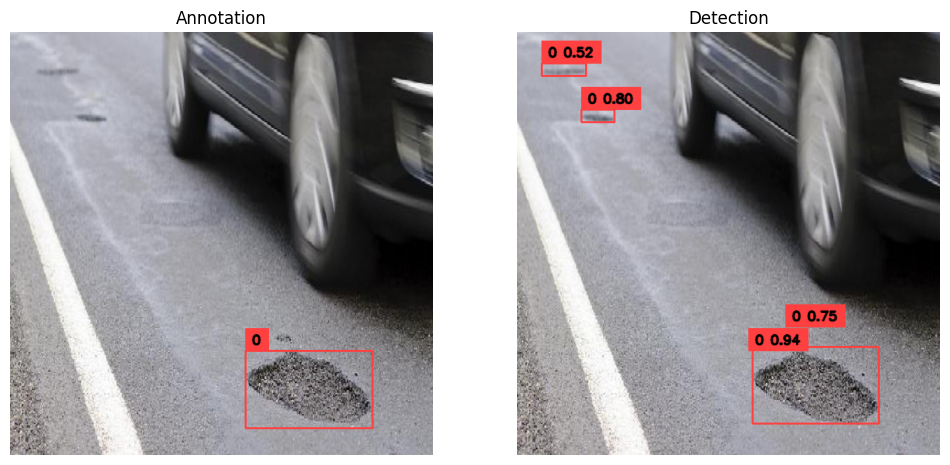

In [ ]:
from rfdetr import RFDETRBase
import supervision as sv
from PIL import Image
import numpy as np

path, image, annotations = ds[0]
image = Image.open(path)

detections = model.predict(np.array(image), threshold=0.5)

text_scale = sv.calculate_optimal_text_scale(resolution_wh=image.size)
thickness = sv.calculate_optimal_line_thickness(resolution_wh=image.size)

bbox_annotator = sv.BoxAnnotator(thickness=thickness)
label_annotator = sv.LabelAnnotator(
    text_color=sv.Color.BLACK,
    text_scale=text_scale,
    text_thickness=thickness,
    smart_position=True)

annotations_labels = [
    f"{ds.classes[class_id]}"
    for class_id
    in annotations.class_id
]

detections_labels = [
    f"{ds.classes[class_id]} {confidence:.2f}"
    for class_id, confidence
    in zip(detections.class_id, detections.confidence)
]

annotation_image = image.copy()
annotation_image = bbox_annotator.annotate(annotation_image, annotations)
annotation_image = label_annotator.annotate(annotation_image, annotations, annotations_labels)

detections_image = image.copy()
detections_image = bbox_annotator.annotate(detections_image, detections)
detections_image = label_annotator.annotate(detections_image, detections, detections_labels)

sv.plot_images_grid(images=[annotation_image, detections_image], grid_size=(1, 2), titles=["Annotation", "Detection"])

In [ ]:
# Fix the Annotation labeling from '0' to 'Pothole'
annotations_labels = [
    "Pothole"
    for _ in annotations.class_id
]

detections_labels = [
    f"Pothole {confidence:.2f}"
    for confidence in detections.confidence
]

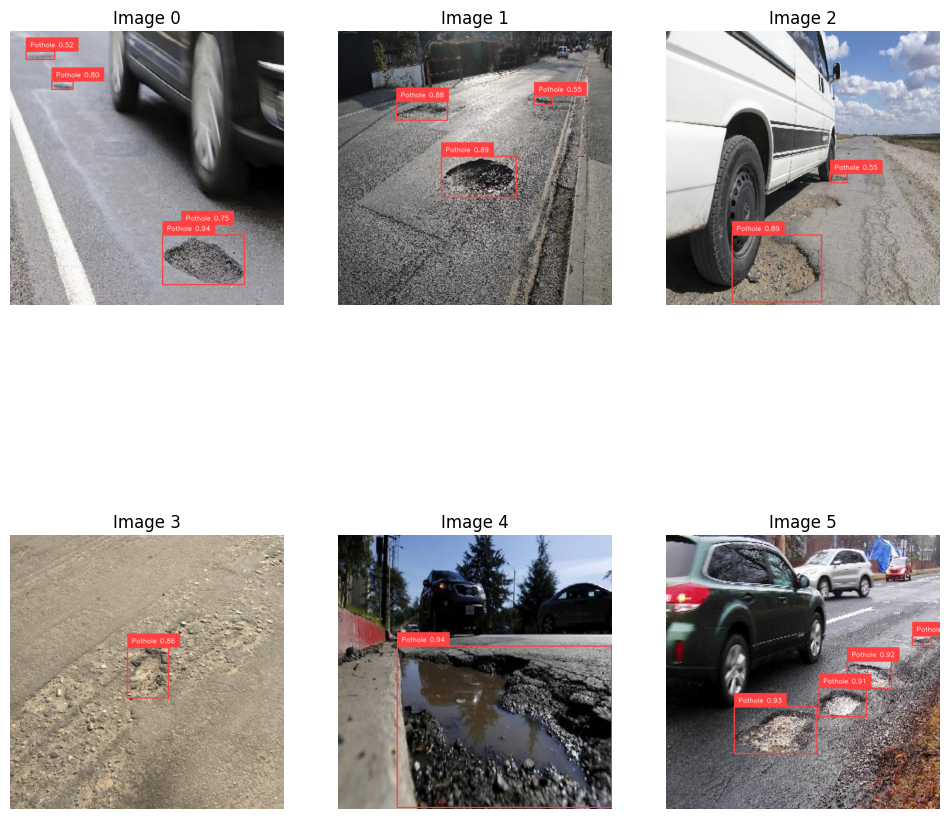

In [ ]:
import supervision as sv
import numpy as np
from PIL import Image

# Annotators
bbox_annotator = sv.BoxAnnotator()
label_annotator = sv.LabelAnnotator()

images = []
titles = []

# number of images to visualize
num_samples = 6

for i in range(num_samples):
    path, image, annotations = ds[i]
    image = Image.open(path)

    # Run inference
    detections = model.predict(np.array(image), threshold=0.5)

    # Labels
    labels = [
        f"Pothole {confidence:.2f}"
        for confidence in detections.confidence
    ]

    # Annotate
    annotated = bbox_annotator.annotate(image.copy(), detections)
    annotated = label_annotator.annotate(annotated, detections, labels)

    images.append(annotated)
    titles.append(f"Image {i}")

# Display grid
sv.plot_images_grid(images=images, grid_size=(2, 3), titles=titles)

## Post Training evaluation

In [ ]:
import supervision as sv
from tqdm import tqdm
from supervision.metrics import MeanAveragePrecision
import numpy as np
from PIL import Image

targets = []
predictions = []

for path, image, annotations in tqdm(ds):
    image = Image.open(path)

    detections = model.predict(np.array(image), threshold=0.5)

    # remove unsupported metadata
    detections.data = {}

    targets.append(annotations)
    predictions.append(detections)

# Compute mAP
map_metric = MeanAveragePrecision()

map_metric.update(predictions=predictions, targets=targets)

results = map_metric.compute()

print(results)

100%|██████████| 67/67 [00:07<00:00,  8.87it/s]

Average Precision (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.440
Average Precision (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.654
Average Precision (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.487
Average Precision (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.037
Average Precision (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.347
Average Precision (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.592


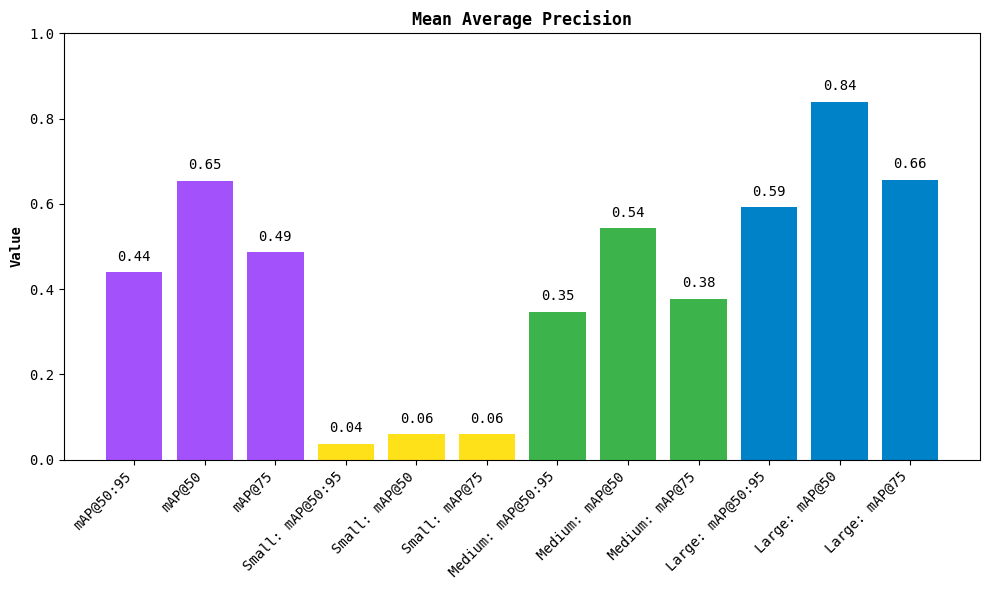

In [ ]:
map_metric = MeanAveragePrecision()
map_result = map_metric.update(predictions, targets).compute()

map_result.plot()

### 📊 Mean Average Precision (mAP) Visualization Interpretation

The bar chart provides a detailed breakdown of model performance across different IoU thresholds and object sizes.

---

### 🔹 Overall Performance

- **mAP (0.50:0.95): 0.44**  
- **mAP@50: 0.65**  
- **mAP@75: 0.49**

- The model performs strongly at **lower IoU thresholds (0.50)**, indicating good detection capability.
- Performance drops at higher IoU (0.75), suggesting **bounding box precision can be improved**.

---

### 🔹 Performance by Object Size

#### 🟡 Small Objects
- Extremely low performance (~0.04–0.06)
- Indicates the model struggles to detect **small potholes**
- Likely due to:
  - low resolution features
  - insufficient representation in training data

#### 🟢 Medium Objects
- Moderate performance (~0.35–0.54)
- Model can detect these reasonably well, but with some inconsistency

#### 🔵 Large Objects
- Strong performance (~0.59–0.84)
- Large potholes are detected **accurately and consistently**

---

### 🧠 Key Insights

- **Detection strength scales with object size**  
  → Larger potholes = easier detection  
  → Smaller potholes = major challenge  

- **Precision vs Localization Trade-off**  
  High mAP@50 vs lower mAP@75 shows:
  - good detection presence  
  - weaker bounding box tightness  

- **Model Bias Toward Prominent Features**  
  The model is better at detecting visually obvious potholes and struggles with subtle or distant ones.

---

### ⚠️ Implications

- The model is **reliable for real-world deployment** where potholes are clearly visible.
- However, it may **miss smaller or early-stage road damage**, which could be critical in preventive maintenance scenarios.

---

### ✅ Conclusion

The model demonstrates **strong detection capability for medium-to-large potholes**, with clear limitations in small object detection and precise localization. Addressing these gaps would further enhance robustness and real-world applicability.

### Confusion Matrix

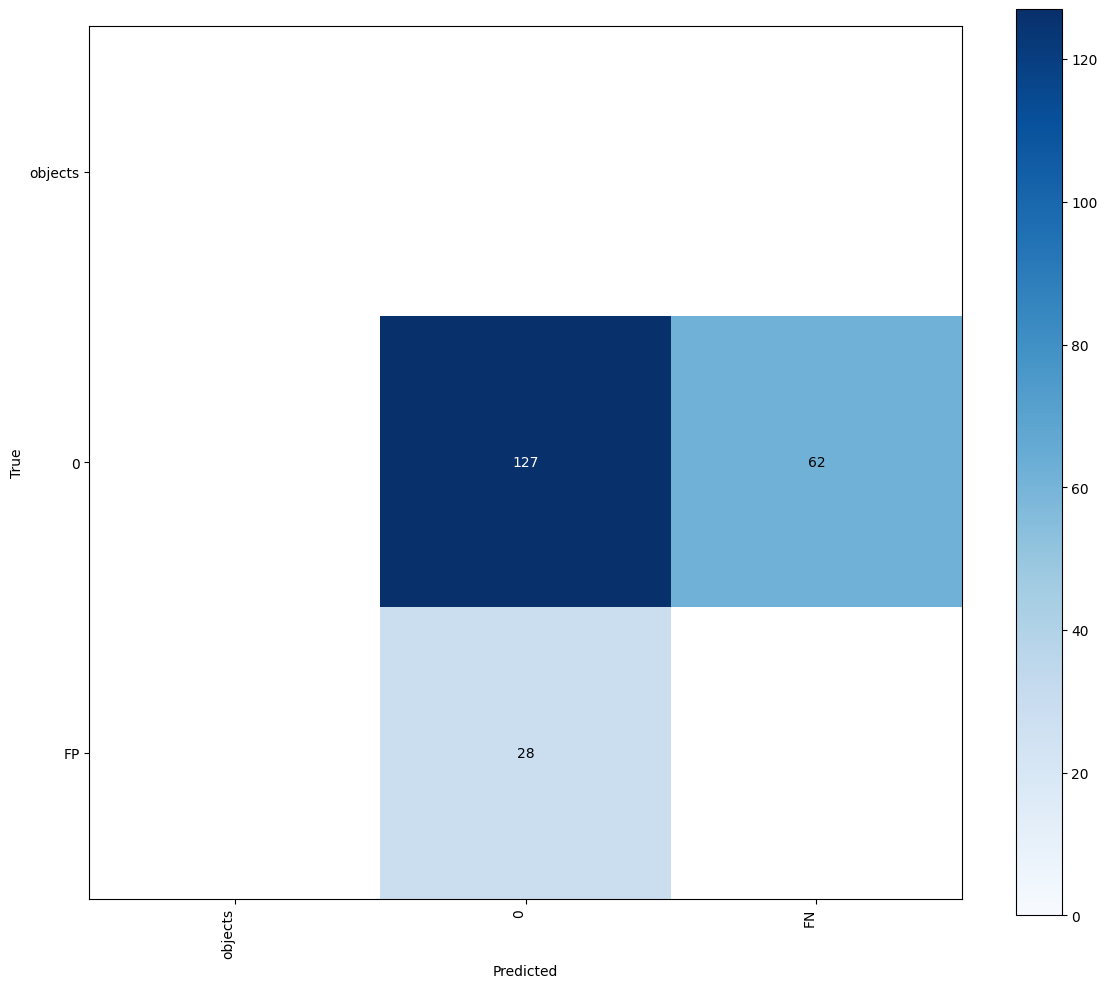

In [ ]:
confusion_matrix = sv.ConfusionMatrix.from_detections(
    predictions=predictions,
    targets=targets,
    classes=ds.classes
)

_ = confusion_matrix.plot()

### 📊 Confusion Matrix Interpretation

The confusion matrix provides a detailed view of the model’s detection performance by comparing predicted outcomes against actual ground truth labels.

---

### 🔹 Key Values

- **True Positives (TP): 127**  
  → Correctly detected potholes  

- **False Negatives (FN): 62**  
  → Missed potholes (model failed to detect)  

- **False Positives (FP): 28**  
  → Incorrect detections (model predicted potholes where none exist)  

---

### 🧠 Interpretation

- **Strong Detection Capability:**  
  The model successfully detects a majority of potholes (127 correct detections), indicating good learning of pothole features.

- **Moderate Miss Rate (Recall Limitation):**  
  With 62 missed detections, the model does not identify all potholes, aligning with earlier observations of **moderate recall (~0.78)**.

- **Low False Positives (High Precision):**  
  Only 28 incorrect detections suggest the model is conservative and precise, consistent with the **high precision (~0.91)** observed during training.

---

### 📈 Derived Insights

- **Precision-Oriented Model:**  
  The model prioritizes correctness over coverage — it avoids false alarms but misses some potholes.

- **Recall Improvement Needed:**  
  The relatively high number of false negatives indicates room for improvement in detecting less obvious or smaller potholes.

---

### ⚠️ Practical Implications

- Suitable for applications where **false alarms must be minimized**  
- May require enhancement for use cases where **missing potholes is critical** (e.g., road safety monitoring)

---

### ✅ Conclusion

The confusion matrix confirms that the model achieves a **good balance with high precision and moderate recall**, making it reliable but slightly conservative in detecting all potholes.

# Error Analysis

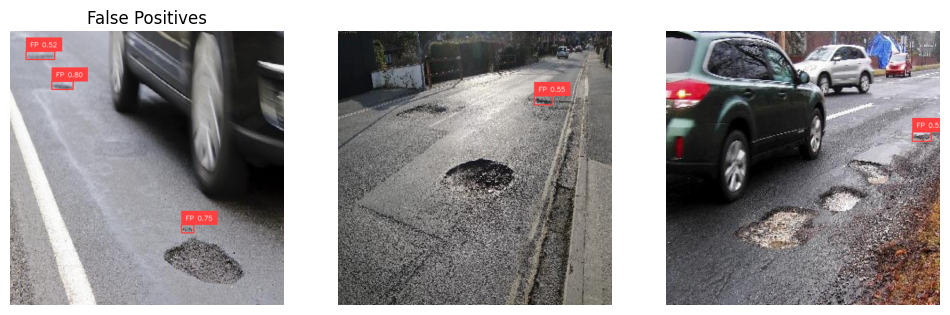

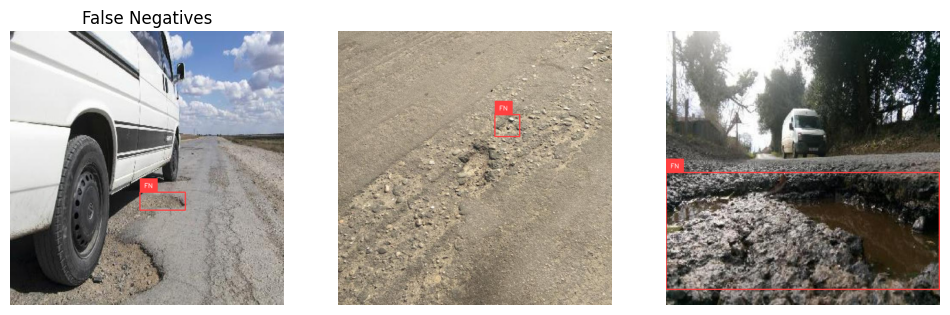

In [ ]:
import supervision as sv
import numpy as np
from PIL import Image

bbox_annotator = sv.BoxAnnotator()
label_annotator = sv.LabelAnnotator()

fp_images = []
fn_images = []

IOU_THRESHOLD = 0.5

def compute_iou(boxA, boxB):
    xA = max(boxA[0], boxB[0])
    yA = max(boxA[1], boxB[1])
    xB = min(boxA[2], boxB[2])
    yB = min(boxA[3], boxB[3])

    interArea = max(0, xB - xA) * max(0, yB - yA)
    boxAArea = (boxA[2] - boxA[0]) * (boxA[3] - boxA[1])
    boxBArea = (boxB[2] - boxB[0]) * (boxB[3] - boxB[1])

    union = boxAArea + boxBArea - interArea
    return interArea / union if union > 0 else 0


for path, image, annotations in ds:
    image = Image.open(path)
    detections = model.predict(np.array(image), threshold=0.5)

    # 🔥 FIX: remove problematic metadata BEFORE slicing
    detections.data = {}

    gt_boxes = annotations.xyxy
    pred_boxes = detections.xyxy

    matched_gt = set()
    matched_pred = set()

    # Match predictions to ground truth
    for i, pbox in enumerate(pred_boxes):
        for j, gtbox in enumerate(gt_boxes):
            if compute_iou(pbox, gtbox) > IOU_THRESHOLD:
                matched_pred.add(i)
                matched_gt.add(j)

    # False Positives
    fp_idx = [i for i in range(len(pred_boxes)) if i not in matched_pred]
    fp = detections[fp_idx] if len(fp_idx) > 0 else None

    # False Negatives
    fn_idx = [i for i in range(len(gt_boxes)) if i not in matched_gt]
    fn = annotations[fn_idx] if len(fn_idx) > 0 else None

    # Collect examples
    if fp is not None and len(fp) > 0 and len(fp_images) < 3:
        img = bbox_annotator.annotate(image.copy(), fp)
        img = label_annotator.annotate(
            img, fp,
            [f"FP {conf:.2f}" for conf in fp.confidence]
        )
        fp_images.append(img)

    if fn is not None and len(fn) > 0 and len(fn_images) < 3:
        img = bbox_annotator.annotate(image.copy(), fn)
        img = label_annotator.annotate(
            img, fn,
            ["FN" for _ in fn.class_id]
        )
        fn_images.append(img)

# Display
sv.plot_images_grid(fp_images, grid_size=(1, len(fp_images)), titles=["False Positives"])
sv.plot_images_grid(fn_images, grid_size=(1, len(fn_images)), titles=["False Negatives"])

### 🔍 Error Analysis: False Positives and False Negatives

To better understand model limitations, visual inspection of false positives (FP) and false negatives (FN) was conducted.

---

### 🔴 False Positives (Incorrect Detections)

False positives occur when the model detects potholes where none exist.

**Observed Causes:**
- **Texture similarity:**  
  Road markings, shadows, and surface irregularities resemble potholes.
- **Lighting effects:**  
  Reflections and wet surfaces create contrast patterns similar to potholes.
- **Blur and motion:**  
  Moving vehicles introduce visual noise, leading to incorrect detections.
- **Edge patterns:**  
  Road boundaries and worn-out patches are sometimes misclassified.

**Insight:**  
The model is sensitive to **visual patterns resembling potholes**, even when semantic context is absent.

---

### 🔵 False Negatives (Missed Detections)

False negatives occur when actual potholes are not detected.

**Observed Causes:**
- **Small object size:**  
  Small or distant potholes are difficult to detect (consistent with low small-object mAP).
- **Low contrast surfaces:**  
  Potholes blending with the road surface are harder to distinguish.
- **Irregular shapes:**  
  Non-uniform or shallow potholes are less recognizable.
- **Occlusion and perspective:**  
  Potholes partially hidden by vehicles or captured at low angles are missed.
- **Complex terrain:**  
  Gravel or damaged roads reduce feature clarity.

**Insight:**  
The model struggles with **subtle, small, or poorly defined potholes**, leading to missed detections.

---

### 📊 Connection to Quantitative Results

These visual errors align with earlier metrics:

- **Low small-object performance (~0.04 mAP):**  
  Explains missed detections of small potholes (FN)

- **High precision (~0.91):**  
  Few false positives overall, but when they occur, they are due to strong visual similarity

- **Moderate recall (~0.78):**  
  Reflects the number of missed potholes observed in FN cases

---

### ⚠️ Key Insight

The model performs well on **clear, well-defined potholes**, but struggles with:
- small-scale defects  
- low-contrast surfaces  
- visually ambiguous road textures  

---

### ✅ Recommendations for Improvement

- Increase training data for **small and subtle potholes**
- Apply **data augmentation** (blur, brightness, contrast)
- Use **higher resolution inputs**
- Fine-tune detection thresholds to improve recall
- Explore multi-scale or feature-enhanced architectures

---

### 🏁 Conclusion

The error analysis reveals that model limitations are primarily driven by **visual ambiguity and scale sensitivity**, which is consistent with both qualitative observations and quantitative evaluation metrics.

# **Hyperparameter tuning**

In [ ]:
from rfdetr import RFDETRBase

model = RFDETRBase()

history = []

def callback2(data):
    history.append(data)

model.callbacks["on_fit_epoch_end"].append(callback2)

model.train(
    dataset_dir=dataset_path,   # use your drive path
    epochs=50,                  # ↑ longer training
    batch_size=4,
    grad_accum_steps=4,
    lr=5e-5,                    # ↓ smaller LR (more stable DETR training)
)

[2026-04-09 19:03:10] [INFO] rf-detr - File rf-detr-base.pth already exists with correct MD5 hash.
[2026-04-09 19:03:11] [INFO] rf-detr - File rf-detr-base.pth already exists with correct MD5 hash.
[2026-04-09 19:03:14] [INFO] rf-detr - File rf-detr-base.pth already exists with correct MD5 hash.


[2026-04-09 19:03:15] [WARNING] rf-detr - Checkpoint has 90 classes but model is configured for 2. The detection head will be re-initialized to 2 classes.
INFO:pytorch_lightning.utilities.rank_zero:Using bfloat16 Automatic Mixed Precision (AMP)
INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


[2026-04-09 19:03:16] [INFO] rf-detr - Building Roboflow train dataset with square resize at resolution 560
[2026-04-09 19:03:16] [INFO] rf-detr - Using multi-scale training with square resize and scales: [840]
[2026-04-09 19:03:16] [INFO] rf-detr - Built 1 Albumentations transforms from config
[2026-04-09 19:03:16] [INFO] rf-detr - Built 1 Albumentations transforms from config
loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
[2026-04-09 19:03:16] [INFO] rf-detr - Building Roboflow val dataset with square resize at resolution 560
[2026-04-09 19:03:16] [INFO] rf-detr - Using multi-scale training with square resize and scales: [840]
[2026-04-09 19:03:16] [INFO] rf-detr - Built 1 Albumentations transforms from config


INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


loading annotations into memory...
Done (t=0.00s)
creating index...
index created!


INFO:pytorch_lightning.utilities.rank_zero:Loading `train_dataloader` to estimate number of stepping batches.


┏━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name        ┃ Type         ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model       │ LWDETR       │ 31.9 M │ train │     0 │
│ 1 │ criterion   │ SetCriterion │      0 │ train │     0 │
│ 2 │ postprocess │ PostProcess  │      0 │ train │     0 │
└───┴─────────────┴──────────────┴────────┴───────┴───────┘

Trainable params: 31.9 M                                                                                           
Non-trainable params: 0                                                                                            
Total params: 31.9 M                                                                                               
Total estimated model params size (MB): 127                                                                        
Modules in train mode: 466                                                                                         
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

[2026-04-09 19:03:19] [INFO] rf-detr - Best EMA mAP improved to 0.0276 (epoch 0)
[2026-04-09 19:06:07] [INFO] rf-detr - Best regular mAP saved to /content/output/checkpoint_best_regular.pth (epoch 0)
[2026-04-09 19:06:08] [INFO] rf-detr - Best EMA mAP improved to 0.4875 (epoch 0)
[2026-04-09 19:09:10] [INFO] rf-detr - Best regular mAP saved to /content/output/checkpoint_best_regular.pth (epoch 1)
[2026-04-09 19:09:10] [INFO] rf-detr - Best EMA mAP improved to 0.5621 (epoch 1)
[2026-04-09 19:12:03] [INFO] rf-detr - Best regular mAP saved to /content/output/checkpoint_best_regular.pth (epoch 2)
[2026-04-09 19:12:09] [INFO] rf-detr - Best EMA mAP improved to 0.5771 (epoch 2)
[2026-04-09 19:14:47] [INFO] rf-detr - Best regular mAP saved to /content/output/checkpoint_best_regular.pth (epoch 3)
[2026-04-09 19:14:51] [INFO] rf-detr - Best EMA mAP improved to 0.5835 (epoch 3)
[2026-04-09 19:17:54] [INFO] rf-detr - Best regular mAP saved to /content/output/checkpoint_best_regular.pth (epoch 4)


### Inference with Custom Model on Videos

In [ ]:
import locale
locale.getpreferredencoding = lambda: "UTF-8"

In [ ]:
!gdown "https://drive.google.com/uc?id=1iMitK9VCUWmBcZiiEPHK1d2pydALof6s&confirm=t"

Downloading...
From: https://drive.google.com/uc?id=1iMitK9VCUWmBcZiiEPHK1d2pydALof6s&confirm=t
To: /content/demo.mp4
100% 4.39M/4.39M [00:00<00:00, 4.85MB/s]


In [ ]:
classes = {1:"pothole"}

In [ ]:
# Define input and output video paths
SOURCE_VIDEO_PATH = "/content/demo.mp4"  # Change this to your input video path
TARGET_VIDEO_PATH = "/content/output_video.mp4"  # Change this to your desired output path

# Create a generator for video frames
frame_generator = sv.get_video_frames_generator(SOURCE_VIDEO_PATH)

# Get video information (resolution, fps, etc.)
video_info = sv.VideoInfo.from_video_path(SOURCE_VIDEO_PATH)

# Process the video frame by frame
with sv.VideoSink(TARGET_VIDEO_PATH, video_info) as sink:
    for frame in tqdm(frame_generator, desc="Processing video"):
        # Get detections using RFDETRBase model
        detections = model.predict(frame, threshold=0.5, iou=0.1)

        # Map numeric class IDs to class names for labels
        labels = []
        for class_id in detections.class_id:
            # Get class name if exists in mapping
            class_name = classes.get(class_id)
            #print("CLass Name", class_name)
            labels.append(class_name)

        # Create annotated frame
        annotated_frame = frame.copy()

        # Apply box annotations
        annotated_frame = sv.BoxAnnotator().annotate(scene=annotated_frame, detections=detections)

        # Apply label annotations with proper class names
        annotated_frame = sv.LabelAnnotator(text_thickness=2).annotate(
            scene=annotated_frame,
            detections=detections,
            labels=labels
        )

        # Write the annotated frame to output video
        sink.write_frame(annotated_frame)

print(f"Video processing complete. Output saved to {TARGET_VIDEO_PATH}")

Processing video: 324it [00:20, 15.44it/s]

Video processing complete. Output saved to /content/output_video.mp4


### Display the Output Video

In [ ]:
!rm '/content/result_compressed.mp4'

rm: cannot remove '/content/result_compressed.mp4': No such file or directory


In [ ]:
from IPython.display import HTML
from base64 import b64encode
import os

# Input video path
save_path = f'/content/output_video.mp4'

# Compressed video path
compressed_path = "/content/result_compressed.mp4"

os.system(f"ffmpeg -i {save_path} -vcodec libx264 {compressed_path}")

# Show video
mp4 = open(compressed_path,'rb').read()
data_url = "data:video/mp4;base64," + b64encode(mp4).decode()
HTML("""
<video width=400 controls>
      <source src="%s" type="video/mp4">
</video>
""" % data_url)

### Load and run fine-tuned model


In [ ]:
!gdown "https://drive.google.com/uc?id=1-3aaHkPwGCy2heR_uvHo_ImQ1loO6T1x&confirm=t"

Downloading...
From: https://drive.google.com/uc?id=1-3aaHkPwGCy2heR_uvHo_ImQ1loO6T1x&confirm=t
To: /content/checkpoint_best_total.pth
100% 369M/369M [00:06<00:00, 53.1MB/s]


[2026-03-13 13:07:00] [INFO] rf-detr - Loading pretrain weights


[2026-03-13 13:07:00] [WARNING] rf-detr - Reinitializing detection head with 1 classes based on pretrained weights, configured for 90.
[2026-03-13 13:07:00] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. You can optimize the model for inference by calling model.optimize_for_inference().


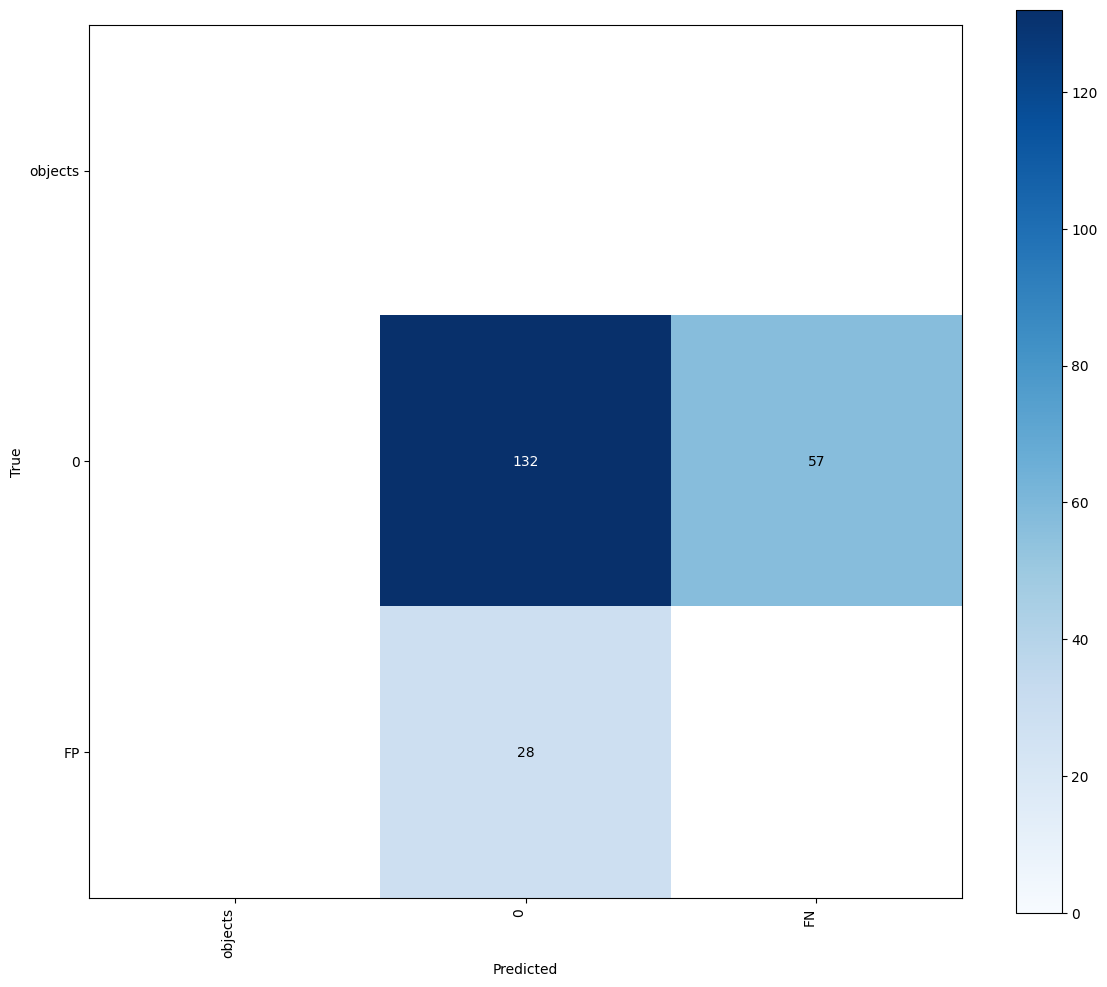

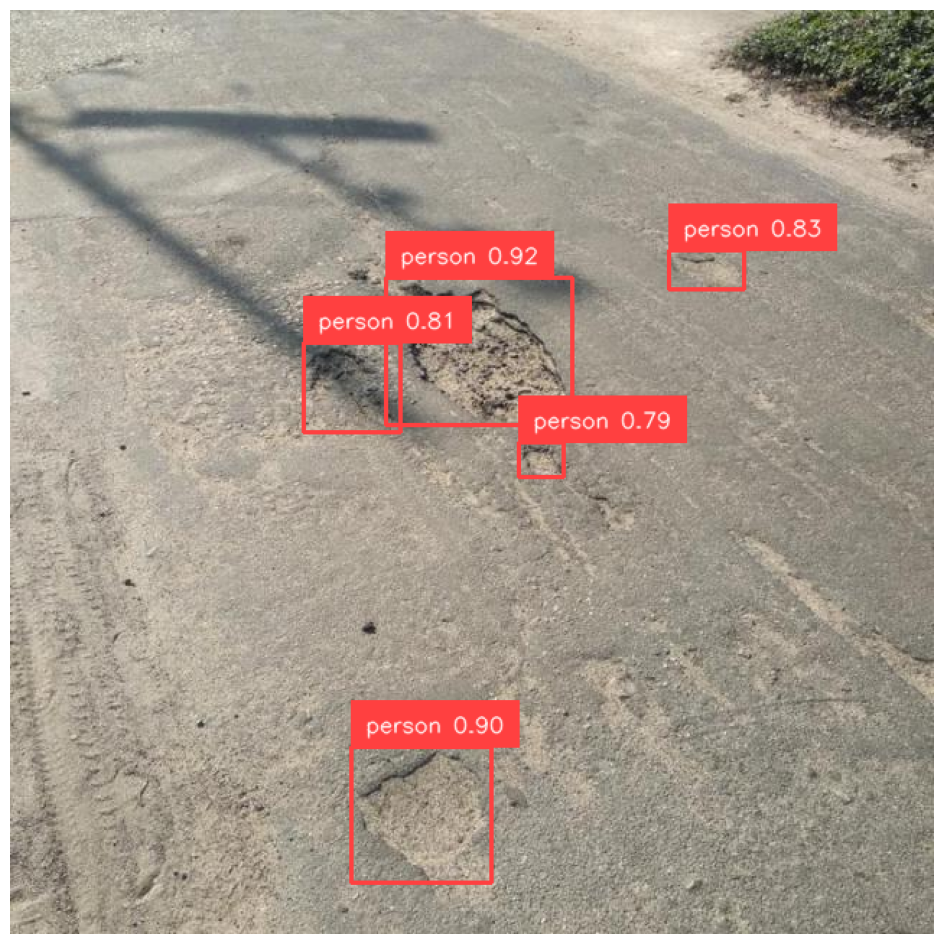

In [ ]:
import io
import requests
import supervision as sv
from PIL import Image
from rfdetr import RFDETRBase
from rfdetr.util.coco_classes import COCO_CLASSES

model = RFDETRBase(pretrain_weights="/content/checkpoint_best_total.pth")

image = Image.open("/content/Potholes-Detection-1/test/img-108_jpg.rf.fb2077bd1f912ba69ff9c156746cc3dc.jpg")
detections = model.predict(image, threshold=0.5)

labels = [
    f"{COCO_CLASSES[class_id]} {confidence:.2f}"
    for class_id, confidence
    in zip(detections.class_id, detections.confidence)
]

annotated_image = image.copy()
annotated_image = sv.BoxAnnotator().annotate(annotated_image, detections)
annotated_image = sv.LabelAnnotator().annotate(annotated_image, detections, labels)

sv.plot_image(annotated_image)

In [ ]:
import os

# Define the path to your backup folder
path = '/content/drive/MyDrive/ZINDUA'

# List all items in the folder
if os.path.exists(path):
    print(f"--- Contents of {path} ---")
    items = os.listdir(path)
    for item in sorted(items):
        item_path = os.path.join(path, item)
        # Check if it's a folder or a file to make the list easier to read
        if os.path.isdir(item_path):
            print(f"[FOLDER] {item}")
        else:
            # Show file size in MB for the checkpoints
            size = os.path.getsize(item_path) / (1024 * 1024)
            print(f"[FILE]   {item} ({size:.2f} MB)")
else:
    print(f"❌ Error: The folder {path} was not found. Please double-check the name in your Drive.")

--- Contents of /content/drive/MyDrive/ZINDUA ---
[FILE]   Fine_Tuning_RF_DETR_Custom_Dataset_Complete (2).ipynb (4.27 MB)
[FOLDER] Potholes-Detection-1
[FILE]   checkpoint_best_total.pth (351.65 MB)
[FILE]   demo.mp4 (4.18 MB)
[FILE]   output_video.mp4 (7.04 MB)
[FILE]   result_compressed.mp4 (3.10 MB)
[FILE]   rf-detr-base.pth (355.32 MB)


[2026-03-13 13:41:42] [INFO] rf-detr - Loading pretrain weights


[2026-03-13 13:41:43] [WARNING] rf-detr - Reinitializing detection head with 1 classes based on pretrained weights, configured for 2.
[2026-03-13 13:41:43] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. You can optimize the model for inference by calling model.optimize_for_inference().


✅ Model brain loaded successfully from Drive using pretrain_weights!
Showing results for: /content/drive/MyDrive/ZINDUA/Potholes-Detection-1/test/img-48_jpg.rf.e97b28b2fa47e0aa7ce09c7605e4a836.jpg


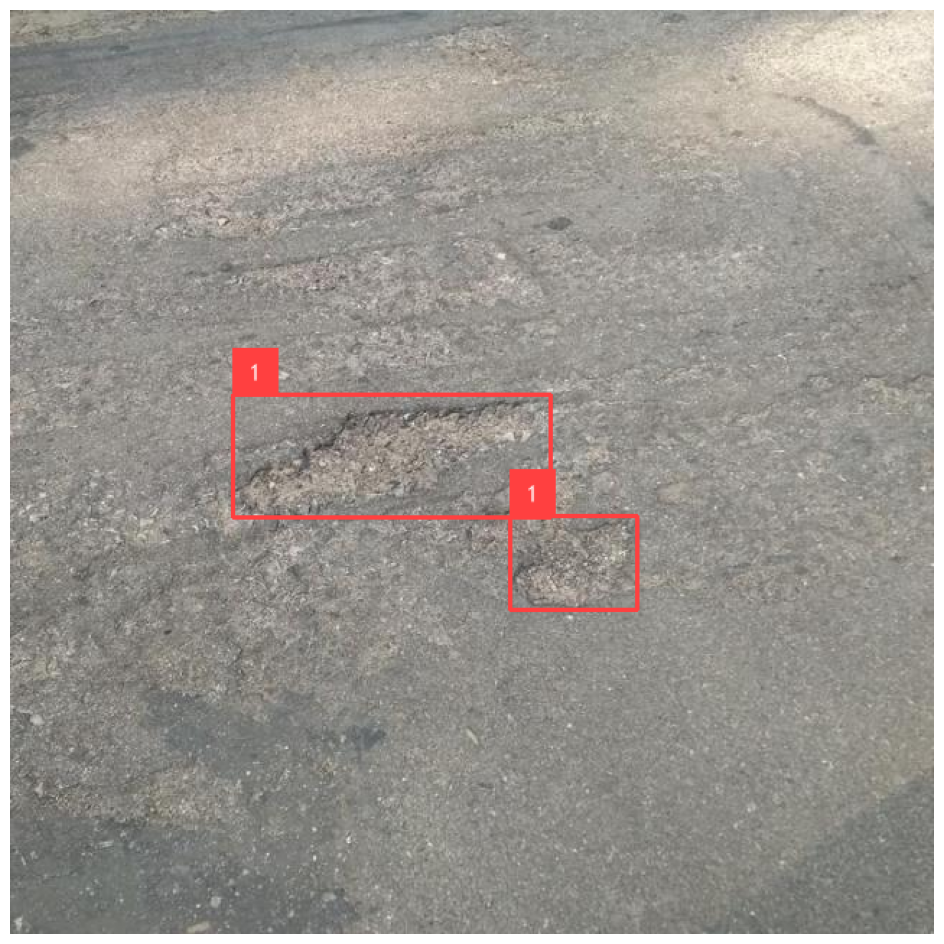

In [ ]:
from rfdetr import RFDETRBase
import os
import supervision as sv
from PIL import Image

# 1. Point to your saved 'Brain'
best_model_path = '/content/drive/MyDrive/ZINDUA/checkpoint_best_total.pth'

# 2. Load the model correctly using the allowed parameter 'pretrain_weights'
# We also specify num_classes=2 so it matches your trained architecture
model = RFDETRBase(pretrain_weights=best_model_path, num_classes=2)
print("✅ Model brain loaded successfully from Drive using pretrain_weights!")

# 3. Find a test image in your Potholes folder
# Let's search specifically for the 'test' or 'valid' image folder inside your Drive
base_path = '/content/drive/MyDrive/ZINDUA/Potholes-Detection-1'
image_folder = os.path.join(base_path, 'test')

if not os.path.exists(image_folder):
    image_folder = os.path.join(base_path, 'valid')

# Get all images in that folder
images = [f for f in os.listdir(image_folder) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]

if images:
    sample_image_path = os.path.join(image_folder, images[0])
    image = Image.open(sample_image_path)

    # 4. Predict and Visualize
    detections = model.predict(image, threshold=0.4)

    box_annotator = sv.BoxAnnotator()
    label_annotator = sv.LabelAnnotator()

    annotated_image = box_annotator.annotate(scene=image.copy(), detections=detections)
    annotated_image = label_annotator.annotate(scene=annotated_image, detections=detections)

    print(f"Showing results for: {sample_image_path}")
    sv.plot_image(annotated_image)
else:
    print("❌ No images found in the dataset folder on your Drive.")

In [ ]:
import supervision as sv

# 1. Define paths
SOURCE_VIDEO_PATH = "/content/drive/MyDrive/ZINDUA/demo.mp4"
TARGET_VIDEO_PATH = "/content/drive/MyDrive/ZINDUA/demo_processed.mp4"

# 2. Get video info
video_info = sv.VideoInfo.from_video_path(SOURCE_VIDEO_PATH)
print(f"Processing video: {SOURCE_VIDEO_PATH}")
print(f"Resolution: {video_info.resolution_wh}, FPS: {video_info.fps}")

# 3. Define the processing function (runs on every single frame)
def process_frame(scene):
    # Predict potholes on the current frame
    detections = model.predict(scene, threshold=0.4)

    # Setup annotators
    box_annotator = sv.BoxAnnotator()
    label_annotator = sv.LabelAnnotator()

    # Draw on the frame
    annotated_frame = box_annotator.annotate(scene=scene.copy(), detections=detections)
    annotated_frame = label_annotator.annotate(scene=annotated_frame, detections=detections)

    return annotated_frame

# 4. Start the heavy lifting (this may take a few minutes)
sv.process_video(
    source_path=SOURCE_VIDEO_PATH,
    target_path=TARGET_VIDEO_PATH,
    callback=process_frame
)

print(f"✅ Finished! Processed video saved to: {TARGET_VIDEO_PATH}")

Processing video: /content/drive/MyDrive/ZINDUA/demo.mp4
Resolution: (1280, 720), FPS: 30
